In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
# loading csvs
columns_of_interest = [3,4,5,6,7, 10]
headers = headers = pd.read_csv('/home/hck03/Documents/MS_thesis/tracking_output/Experiment data summary - 1C-4N.csv', nrows=0, usecols=columns_of_interest).columns.tolist()
print(headers)
df_1c_4n = pd.read_csv('/home/hck03/Documents/MS_thesis/tracking_output/Experiment data summary - 1C-4N.csv', header=0, usecols=columns_of_interest).to_numpy()
df_2c_3n = pd.read_csv('/home/hck03/Documents/MS_thesis/tracking_output/Experiment data summary - 2C-3N.csv', header=0, usecols=columns_of_interest).to_numpy()
df_3c_2n = pd.read_csv('/home/hck03/Documents/MS_thesis/tracking_output/Experiment data summary - 3C-2N.csv', header=0, usecols=columns_of_interest).to_numpy()
df_4c_1n = pd.read_csv('/home/hck03/Documents/MS_thesis/tracking_output/Experiment data summary - 4C-1N.csv', header=0, usecols=columns_of_interest).to_numpy()

grand_time_array = np.stack((df_1c_4n, df_2c_3n, df_3c_2n, df_4c_1n), axis=0)/100

treatments = ['1C-4N', '2C-3N', '3C-2N', '4C-1N']

['Light on Frame no.', 'First fish cross frame', 'No. crossed (first crossing)', 'Last fish cross frame', 'Light off frame no.', 'Complete Behavior observed']


In [6]:
# finding latency (l)
l_light_on_to_first_fish_crossing = np.squeeze(grand_time_array[:,:,1] - grand_time_array[:,:,0])
l_last_fish_to_first_fish_crossing = np.squeeze(grand_time_array[:,:,3] - grand_time_array[:,:,1]).astype(float)

l_last_fish_to_first_fish_crossing[l_last_fish_to_first_fish_crossing < 0] = np.nan
l_light_on_to_first_fish_crossing[l_light_on_to_first_fish_crossing < 0] = np.nan

In [7]:
np.nanmax(l_light_on_to_first_fish_crossing[0, :])

np.float64(9.709999999999999)

(4,)


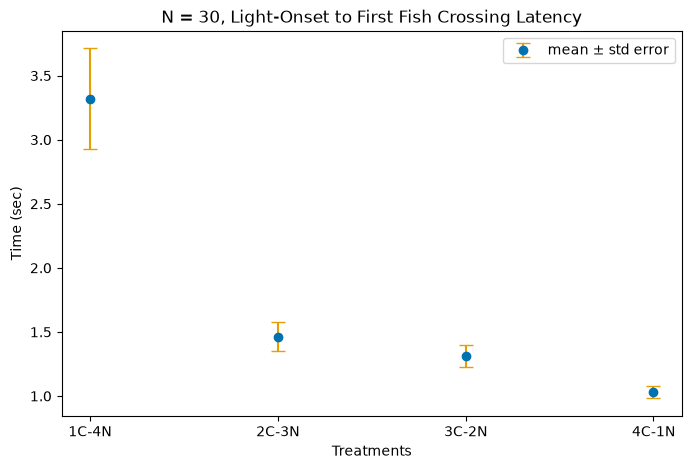

In [8]:
import seaborn as sns
treament_mean_1 = np.squeeze(np.nanmean(l_light_on_to_first_fish_crossing, axis=1))
treament_std_1 = np.squeeze(np.nanstd(l_light_on_to_first_fish_crossing, axis=1))/np.sqrt(30)

print(treament_mean_1.shape)
row_indices = np.arange(grand_time_array.shape[0])

plt.figure(figsize=(8,5))
# sns.violinplot(
#     data=l_light_on_to_first_fish_crossing.T, 
#     # palette='colorblind'
# )
plt.title("N = 30, Light-Onset to First Fish Crossing Latency")
plt.errorbar(x = row_indices, y = treament_mean_1, yerr = treament_std_1, fmt = 'o', color = '#0072B2', ecolor = '#E69F00', capsize = 5, label = "mean ± std error")
plt.xticks(ticks=row_indices, labels=treatments)
plt.ylabel("Time (sec)")
plt.xlabel("Treatments")
plt.legend()
plt.savefig("Light-Onset_to_First_Fish_Crossing_Latency.png", dpi=300, bbox_inches='tight')
plt.show()

In [9]:
from scipy import stats

rank_array = np.ones(l_light_on_to_first_fish_crossing.shape)
rank_array[1,:] = 2
rank_array[2,:] = 3
rank_array[3,:] = 4

flat_rank = np.ravel(rank_array)
flat_data = np.ravel(l_light_on_to_first_fish_crossing)

correlation, p_val = stats.spearmanr(flat_rank, flat_data)

print(correlation, p_val)


nan nan


/tmp/ipykernel_10960/1662244497.py:42: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_10960/1662244497.py:42: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(


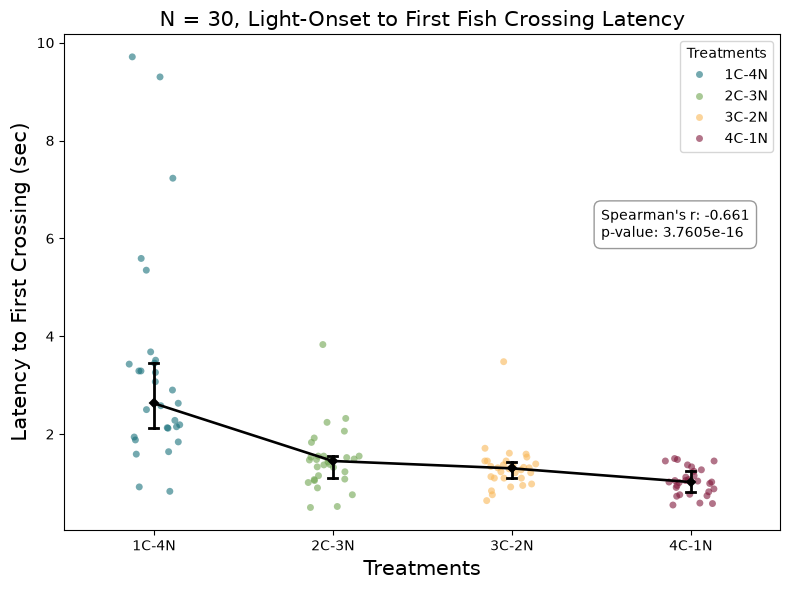

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Accessible palette for 1C, 2C, 3C, 4C
accessible_palette = ["#17707B", "#70A551", "#F9B859", "#80173A"]
treatment_labels = ["1C-4N", "2C-3N", "3C-2N", "4C-1N"]

latency_120 = l_light_on_to_first_fish_crossing.flatten()
c_counts = np.repeat([1, 2, 3, 4], 30)

df = pd.DataFrame({
    'C_count': c_counts,
    'latency_sec': latency_120
})

df = df.dropna(subset=['latency_sec'])

# Calculate the Spearman correlation for the text box
rho, p_val = stats.spearmanr(df['C_count'], df['latency_sec'])

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Jittered raw data
# Added hue="C_count" to automatically generate legend elements
sns.stripplot(
    data=df, 
    x="C_count", 
    y="latency_sec", 
    hue="C_count",
    palette=accessible_palette,
    alpha=0.6, 
    jitter=0.15, 
    size=5, 
    ax=ax,
    zorder=1
)

# 2. Median trendline with IQR error bars
sns.pointplot(
    data=df, 
    x="C_count", 
    y="latency_sec", 
    estimator=np.median, 
    errorbar=("pi", 50), 
    color="black",       
    markers="D",         
    scale=0.7,
    errwidth=2,
    capsize=0.05,
    ax=ax,
    zorder=2  # Changed to 2 so the trendline sits clearly on top of the dots
)

ax.set_title("N = 30, Light-Onset to First Fish Crossing Latency", fontsize=15)
ax.set_xlabel("Treatments", fontsize=15)
ax.set_ylabel("Latency to First Crossing (sec)", fontsize=15)
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(treatment_labels)

# Configure the Legend
# Extracts the handles from stripplot and applies your custom labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:4], treatment_labels, title="Treatments", loc="upper right")

# Add the Text Box with Correlation Stats
# Placed in the upper left corner to avoid overlapping the legend
stats_text = f"Spearman's r: {rho:.3f}\np-value: {p_val:.4e}"
bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(0.75, 0.65, stats_text, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='left', bbox=bbox_props)

plt.tight_layout()

# Save the figure as a high-res PNG before calling plt.show()
plt.savefig("latency_trend_plot.png", dpi=300, bbox_inches="tight")
plt.show()

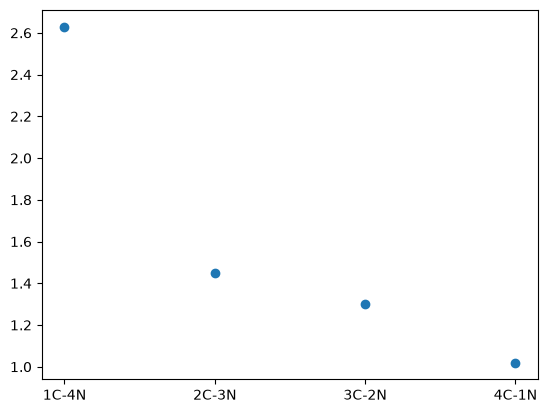

In [11]:
treatment_median_1 = np.nanmedian(l_light_on_to_first_fish_crossing, axis=1)

plt.scatter(row_indices, treatment_median_1)
plt.xticks(ticks=row_indices, labels=treatments)
# plt.ylim(0, 12)
plt.show()


In [9]:
non_nan_mask = ~np.isnan(l_last_fish_to_first_fish_crossing)

counts_per_row = np.sum(non_nan_mask, axis=1)
print(counts_per_row)

[18 28 28 24]


(4,)


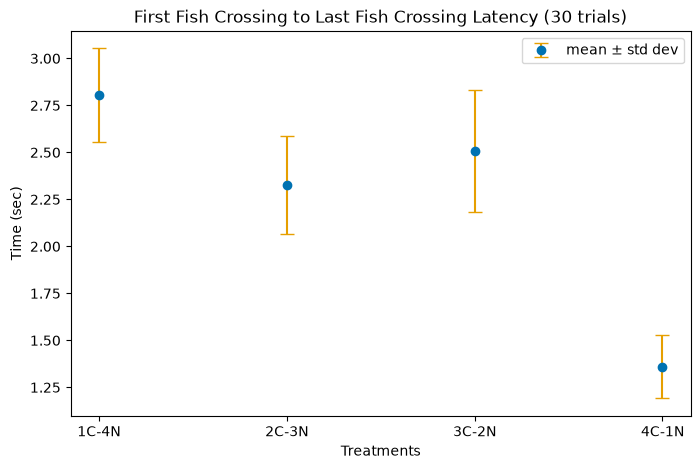

In [10]:
treament_mean_2 = np.squeeze(np.nanmean(l_last_fish_to_first_fish_crossing, axis=1))
treament_std_2 = np.squeeze(np.nanstd(l_last_fish_to_first_fish_crossing, axis=1))

treatment_sem_2 = [treament_std_2[i]/np.sqrt(counts_per_row[i]) for i in range(len(counts_per_row))]
print(treament_mean_1.shape)
row_indices = np.arange(grand_time_array.shape[0])

plt.figure(figsize=(8,5))
plt.title("First Fish Crossing to Last Fish Crossing Latency (30 trials)")
plt.errorbar(x = row_indices, y = treament_mean_2, yerr = treatment_sem_2, fmt = 'o', color = '#0072B2', ecolor = '#E69F00', capsize = 5, label = "mean ± std dev")
plt.xticks(ticks=row_indices, labels=treatments)
plt.ylabel("Time (sec)")
plt.xlabel("Treatments")
plt.legend()
plt.savefig("first_fish_to_last_fish.png", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_9667/3795594202.py:42: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_9667/3795594202.py:42: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(


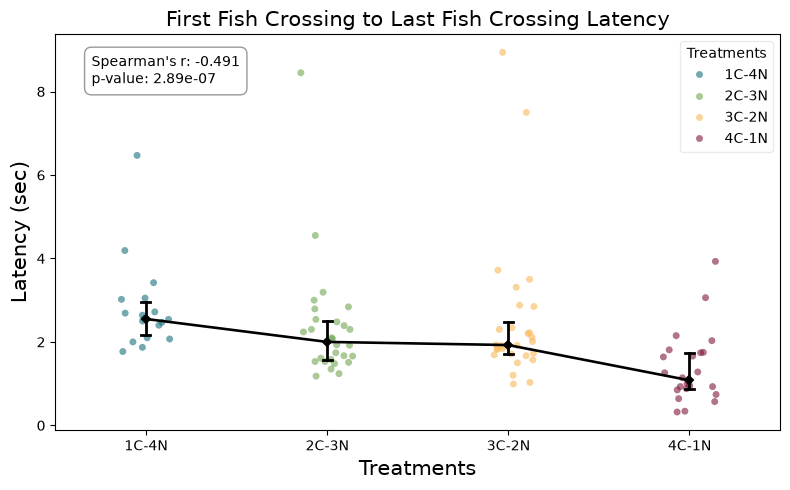

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Flatten the 2D array and create labels
latency_120 = l_last_fish_to_first_fish_crossing.flatten()
c_counts = np.repeat([1, 2, 3, 4], 30)

# 2. Build DataFrame and drop the NaNs (videos where the last fish never crossed)
df = pd.DataFrame({
    'C_count': c_counts,
    'latency_sec': latency_120
})
df = df.dropna(subset=['latency_sec'])

# Calculate correlation on the cleaned data
rho, p_val = stats.spearmanr(df['C_count'], df['latency_sec'])

# 3. Generate the cohesive plot
accessible_palette = ["#17707B", "#70A551", "#F9B859", "#80173A"]
treatment_labels = ["1C-4N", "2C-3N", "3C-2N", "4C-1N"]

fig, ax = plt.subplots(figsize=(8, 5))

# Raw jittered data overlay
sns.stripplot(
    data=df, 
    x="C_count", 
    y="latency_sec", 
    hue="C_count",
    palette=accessible_palette,
    alpha=0.6, 
    jitter=0.15, 
    size=5, 
    ax=ax,
    zorder=1
)

# Median trendline with IQR error bars (Robust to skew)
sns.pointplot(
    data=df, 
    x="C_count", 
    y="latency_sec", 
    estimator=np.median, 
    errorbar=("pi", 50), 
    color="black",       
    markers="D",         
    scale=0.7,
    errwidth=2,
    capsize=0.05,
    ax=ax,
    zorder=2
)

ax.set_title("First Fish Crossing to Last Fish Crossing Latency", fontsize=15)
ax.set_xlabel("Treatments", fontsize=15)
ax.set_ylabel("Latency (sec)", fontsize=15)
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(treatment_labels)

# Legend and Stats Box
handles, labels = ax.get_legend_handles_labels()
leg = ax.legend(handles[:4], treatment_labels, title="Treatments", loc="upper right")

leg.get_frame().set_alpha(0.4) 

stats_text = f"Spearman's r: {rho:.3f}\np-value: {p_val:.2e}"
bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', horizontalalignment='left', bbox=bbox_props)

plt.tight_layout()
plt.savefig("first_fish_to_last_fish.png", dpi=300, bbox_inches='tight')
plt.show()

(4, 30)


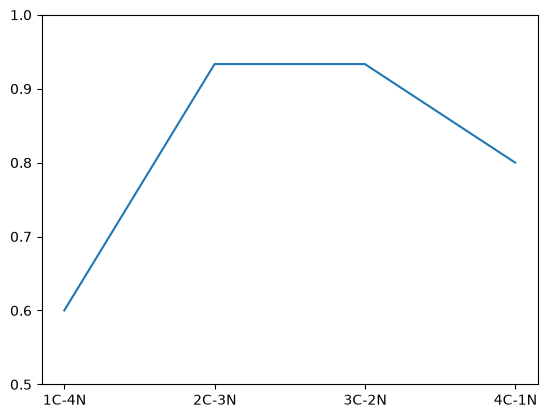

In [85]:
# accuracy

complete_behavior = grand_time_array[:, :, 5]
print(complete_behavior.shape)
fraction = (np.sum(complete_behavior, axis=1)/30)*100

plt.plot(row_indices, fraction)
plt.xticks(ticks=row_indices, labels=treatments)
plt.ylim(0.5, 1.0)
plt.show()

In [81]:
fraction

array([0.006     , 0.00933333, 0.00933333, 0.008     ])